In [1]:
# Import the datasets
import pandas as pd
demo = pd.read_sas("/Users/heidisaldana/Downloads/DEMO_L.xpt")
bmx  = pd.read_sas("/Users/heidisaldana/Downloads/BMX_L.xpt.txt")
bp   = pd.read_sas("/Users/heidisaldana/Downloads/BPXO_L.xpt")
chol = pd.read_sas("/Users/heidisaldana/Downloads/TCHOL_L.xpt")
smok = pd.read_sas("/Users/heidisaldana/Downloads/SMQ_L.xpt")
mcq  = pd.read_sas("/Users/heidisaldana/Downloads/MCQ_L.xpt")
bpq  = pd.read_sas("/Users/heidisaldana/Downloads/BPQ_L.xpt")
diq  = pd.read_sas("/Users/heidisaldana/Downloads/DIQ_L.xpt.txt")


# Merge the datasets
df = demo.merge(bmx, on="SEQN", how="inner") \
         .merge(bp, on="SEQN", how="inner") \
         .merge(chol, on="SEQN", how="inner") \
         .merge(mcq, on="SEQN", how="inner") \
         .merge(smok, on="SEQN", how="inner")\
         .merge(bpq, on="SEQN", how="inner")\
         .merge(diq, on="SEQN", how="inner")
print(df.shape)
df.head()


(6615, 117)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,BPQ080,BPQ101D,DIQ010,DID040,DIQ160,DIQ180,DIQ050,DID060,DIQ060U,DIQ070
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,2.0,2.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,NaN,NaN
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,1.0,1.0,1.0,35.0,NaN,NaN,2.0,NaN,NaN,1.0
3,130386.0,12.0,2.0,1.0,34.0,NaN,1.0,1.0,1.0,NaN,...,2.0,2.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN
4,130387.0,12.0,2.0,2.0,68.0,NaN,3.0,3.0,2.0,NaN,...,1.0,2.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN


## Data Preperation

### Whole dataset preparation

In [4]:
# Output total variables in dataset
print("Total variables:", len(df.columns))
print("\nVariable list:")
for col in df.columns:
    print(col)


Total variables: 117

Variable list:
SEQN
SDDSRVYR
RIDSTATR
RIAGENDR
RIDAGEYR
RIDAGEMN
RIDRETH1
RIDRETH3
RIDEXMON
RIDEXAGM
DMQMILIZ
DMDBORN4
DMDYRUSR
DMDEDUC2
DMDMARTZ
RIDEXPRG
DMDHHSIZ
DMDHRGND
DMDHRAGZ
DMDHREDZ
DMDHRMAZ
DMDHSEDZ
WTINT2YR
WTMEC2YR
SDMVSTRA
SDMVPSU
INDFMPIR
BMDSTATS
BMXWT
BMIWT
BMXRECUM
BMIRECUM
BMXHEAD
BMIHEAD
BMXHT
BMIHT
BMXBMI
BMDBMIC
BMXLEG
BMILEG
BMXARML
BMIARML
BMXARMC
BMIARMC
BMXWAIST
BMIWAIST
BMXHIP
BMIHIP
BPAOARM
BPAOCSZ
BPXOSY1
BPXODI1
BPXOSY2
BPXODI2
BPXOSY3
BPXODI3
BPXOPLS1
BPXOPLS2
BPXOPLS3
WTPH2YR
LBXTC
LBDTCSI
MCQ010
MCQ035
MCQ040
MCQ050
AGQ030
MCQ053
MCQ149
MCQ160A
MCQ195
MCQ160B
MCQ160C
MCQ160D
MCQ160E
MCQ160F
MCQ160M
MCQ170M
MCQ160P
MCQ160L
MCQ170L
MCQ500
MCQ510A
MCQ510B
MCQ510C
MCQ510D
MCQ510E
MCQ510F
MCQ550
MCQ560
MCQ220
MCQ230A
MCQ230B
MCQ230C
MCQ230D
OSQ230
SMQ020
SMQ040
SMD641
SMD650
SMD100MN
SMQ621
SMD630
SMAQUEX2
BPQ020
BPQ030
BPQ150
BPQ080
BPQ101D
DIQ010
DID040
DIQ160
DIQ180
DIQ050
DID060
DIQ060U
DIQ070


In [5]:
# Create missingness summary of all variables in dataset
summary = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean() * 100
})

summary = summary.sort_values("pct_missing", ascending=False)

summary.head(20)
high_missing = summary[summary["pct_missing"] > 50]
high_missing.sort_values("pct_missing", ascending=False)


,n_missing,pct_missing
BMIRECUM,6615,100.000000
RIDAGEMN,6615,100.000000
MCQ149,6615,100.000000
BMXHEAD,6615,100.000000
BMIHEAD,6615,100.000000
BMXRECUM,6615,100.000000
MCQ230D,6613,99.969766
MCQ510B,6611,99.939531
MCQ510E,6603,99.818594
SMD630,6600,99.773243


diabetes

In [7]:
# Determine the output for diabetes
df["DIQ010"].value_counts(dropna=False).sort_index()
# 1 = Yes, diagnosed diabetes, 2 = No diagnosed diabetes, 3 = Borderline diabetes, 9 = Don't know

DIQ010
1.0     871
2.0    5520
3.0     223
9.0       1
Name: count, dtype: int64

In [8]:
# Create corrected diabetes indicator
df["diabetes"] = df["DIQ010"].map({
    1: 1,  # Diagnosed diabetes
    2: 0   # No diagnosed diabetes
})
# Borderline (3), refused (7), don't know (9) and missing responses become NaN

# Check classification
print(df["diabetes"].value_counts(dropna=False))

diabetes
0.0    5520
1.0     871
NaN     224
Name: count, dtype: int64


high cholesterol

In [10]:
# Determine the responses for self-reported high cholesterol
df["BPQ080"].value_counts(dropna=False)
# 1 means yes, 2 means no and 9 means don't know, and there is no missing values

BPQ080
2.0    4041
1.0    2538
9.0      36
Name: count, dtype: int64

In [11]:
# Convert self-reported high cholesterol to binary (0 = No, 1 = Yes)
df["High_Cholesterol"] = df["BPQ080"].map({1: 1, 2: 0})
# Check distribution, including missing values
print(df["High_Cholesterol"].value_counts(dropna=False))

High_Cholesterol
0.0    4041
1.0    2538
NaN      36
Name: count, dtype: int64


diagnosed hypertension

In [13]:
# Determine responses for self-reported diagnosed hypertension
df["BPQ020"].value_counts(dropna=False)
# 1 means yes, 2 means no and 9 means don't know

BPQ020
2.0    4278
1.0    2333
9.0       4
Name: count, dtype: int64

In [14]:
# Create self-reported hypertension indicator
# Preserve missing responses without removing participants
df["HTN_diagnosed"] = df["BPQ020"].map({1: 1, 2: 0})

print(df["HTN_diagnosed"].value_counts(dropna=False))

HTN_diagnosed
0.0    4278
1.0    2333
NaN       4
Name: count, dtype: int64


blood pressure medication use

In [16]:
# Determine the responses for blood pressure medication use
df["BPQ150"].value_counts(dropna=False).sort_index()
# 1 = Yes, 2 = No, 9 = Don't know
# NaN = Missing or question not applicable

BPQ150
1.0    1927
2.0     403
9.0       3
NaN    4282
Name: count, dtype: int64

In [17]:
# Convert blood pressure medication use to binary (0 = No, 1 = Yes)
df["BP_med"] = df["BPQ150"].map({1: 1, 2: 0})

# Check the distribution, including missing values
print(df["BP_med"].value_counts(dropna=False))

BP_med
NaN    4285
1.0    1927
0.0     403
Name: count, dtype: int64


In [18]:
df["BP_medication_adjusted"] = df["BP_med"].copy()

# Participants who reported never being told they had
# high blood pressure were not asked BPQ150.
# Treat this structural missingness as no reported BP medication use.
df.loc[
    (df["BPQ020"] == 2) &
    (df["BPQ150"].isna()),
    "BP_medication_adjusted"
] = 0

# Verify the adjusted medication variable
print(df["BP_medication_adjusted"].value_counts(dropna=False))

BP_medication_adjusted
0.0    4681
1.0    1927
NaN       7
Name: count, dtype: int64


clinical hypertension

In [20]:
# Compute the average for Systolic and Diastolic Blood Pressure among the 3 trials
df["SBP_avg"] = df[["BPXOSY1","BPXOSY2","BPXOSY3"]].mean(axis=1)
df["DBP_avg"] = df[["BPXODI1","BPXODI2","BPXODI3"]].mean(axis=1)
# first trial can be high for people nervous about the procedure so an average is preferred among 3 trials

In [21]:
# Clinical hypertension criteria
# 1 = SBP >= 130, DBP >= 80, or reported BP medication use
# 0 = Both BP measurements below thresholds and no reported medication
# NaN = Insufficient information to classify
import numpy as np

htn_yes = (
    (df["SBP_avg"] >= 130) |
    (df["DBP_avg"] >= 80) |
    (df["BP_medication_adjusted"] == 1)
)

htn_no = (
    (df["SBP_avg"] < 130) &
    (df["DBP_avg"] < 80) &
    (df["BP_medication_adjusted"] == 0)
)

df["HTN_clinical"] = np.select(
    [htn_yes, htn_no],
    [1, 0],
    default=np.nan
)

# Check updated distribution
print(df["HTN_clinical"].value_counts(dropna=False))

HTN_clinical
1.0    3333
0.0    3125
NaN     157
Name: count, dtype: int64


CVD indicators

In [23]:
# Determine the output for Congestive heart failure
df["MCQ160B"].value_counts(dropna=False)

MCQ160B
2.0    5797
NaN     551
1.0     258
9.0       9
Name: count, dtype: int64

In [24]:
# Determine the output for Coronary heart disease
df["MCQ160C"].value_counts(dropna=False)

MCQ160C
2.0    5717
NaN     552
1.0     322
9.0      24
Name: count, dtype: int64

In [25]:
# Determine the output for Angina
df["MCQ160D"].value_counts(dropna=False)

MCQ160D
2.0    5909
NaN     551
1.0     140
9.0      15
Name: count, dtype: int64

In [26]:
# Determine the output for Heart attack
df["MCQ160E"].value_counts(dropna=False)

MCQ160E
2.0    5793
NaN     552
1.0     261
9.0       9
Name: count, dtype: int64

In [27]:
# Determine the output for Stroke
df["MCQ160F"].value_counts(dropna=False)

MCQ160F
2.0    5773
NaN     553
1.0     280
9.0       9
Name: count, dtype: int64

In [28]:
import numpy as np

# Five self-reported cardiovascular conditions
cvd_vars = [
    "MCQ160B",  # Congestive heart failure
    "MCQ160C",  # Coronary heart disease
    "MCQ160D",  # Angina
    "MCQ160E",  # Heart attack
    "MCQ160F"   # Stroke
]

# Identify participants with at least one reported CVD condition
cvd_yes = df[cvd_vars].eq(1).any(axis=1)

# Identify participants who reported no history of all five conditions
cvd_no = df[cvd_vars].eq(2).all(axis=1)

# Create binary CVD outcome while preserving uncertain responses
df["CVD"] = np.select(
    [cvd_yes, cvd_no],
    [1, 0],
    default=np.nan
)

# Examine CVD distribution
print(df["CVD"].value_counts(dropna=False))

CVD
0.0    5263
1.0     773
NaN     579
Name: count, dtype: int64


In [29]:
cvd_vars = ["MCQ160B", "MCQ160C","MCQ160D", "MCQ160E", "MCQ160F"]

print("=== RESPONSE CODE DISTRIBUTIONS ===")

for var in cvd_vars:
    print(f"\n{var}:")
    print(df[var].value_counts(dropna=False).sort_index())

print("\n=== MISSING COUNTS ===")
print(df[cvd_vars].isna().sum())

print("\n=== MISSING PERCENTAGES ===")
print((df[cvd_vars].isna().mean() * 100).round(2))

print("\n=== COMPLETE VS INCOMPLETE CVD RESPONSES ===")
print("All 4 responses available:",
      df[cvd_vars].notna().all(axis=1).sum())

print("At least 1 response missing:",
      (~df[cvd_vars].notna().all(axis=1)).sum())

print("All 4 responses missing:",
      df[cvd_vars].isna().all(axis=1).sum())

=== RESPONSE CODE DISTRIBUTIONS ===

MCQ160B:
MCQ160B
1.0     258
2.0    5797
9.0       9
NaN     551
Name: count, dtype: int64

MCQ160C:
MCQ160C
1.0     322
2.0    5717
9.0      24
NaN     552
Name: count, dtype: int64

MCQ160D:
MCQ160D
1.0     140
2.0    5909
9.0      15
NaN     551
Name: count, dtype: int64

MCQ160E:
MCQ160E
1.0     261
2.0    5793
9.0       9
NaN     552
Name: count, dtype: int64

MCQ160F:
MCQ160F
1.0     280
2.0    5773
9.0       9
NaN     553
Name: count, dtype: int64

=== MISSING COUNTS ===
MCQ160B    551
MCQ160C    552
MCQ160D    551
MCQ160E    552
MCQ160F    553
dtype: int64

=== MISSING PERCENTAGES ===
MCQ160B    8.33
MCQ160C    8.34
MCQ160D    8.33
MCQ160E    8.34
MCQ160F    8.36
dtype: float64

=== COMPLETE VS INCOMPLETE CVD RESPONSES ===
All 4 responses available: 6062
At least 1 response missing: 553
All 4 responses missing: 551


### CVD data preperation

In [31]:
# Standardize effectively zero income-to-poverty ratio values
# Preserve other valid low income-to-poverty ratios
df["INDFMPIR"] = df["INDFMPIR"].mask(
    df["INDFMPIR"].abs() < 1e-10,
    0.0
)

# Verify the cleaning
print("Exact zero values:")
print((df["INDFMPIR"] == 0).sum())

print("\nIncome-to-poverty ratio summary:")
print(df["INDFMPIR"].describe())

Exact zero values:
58

Income-to-poverty ratio summary:
count    5751.000000
mean        2.876887
std         1.659801
min         0.000000
25%         1.370000
50%         2.770000
75%         4.920000
max         5.000000
Name: INDFMPIR, dtype: float64


In [32]:
# Select predictors and CVD outcome
keep_cols_cvd = [
    "RIDAGEYR",      # Age
    "RIAGENDR",      # Sex
    "RIDRETH3",      # Race/ethnicity
    "INDFMPIR",      # Income-to-poverty ratio
    "BMXBMI",        # Body mass index
    "LBXTC",         # Total cholesterol
    "SMQ020",        # Smoked at least 100 cigarettes in lifetime
    "diabetes",      # Diagnosed with diabetes
    "HTN_clinical",  # Clinical hypertension indicator
    "HTN_diagnosed", # hypertension diagnosis
    "High_Cholesterol", # Self-reported high cholesterol
    "CVD"            # Self-reported CVD history
]

# Restrict to adults aged 20+ with known CVD status
df_cvd = df.loc[
    (df["RIDAGEYR"] >= 20) & (df["CVD"].notna()),
    keep_cols_cvd
].copy()

# Check sample size and CVD distribution
print("CVD sample size:", len(df_cvd))
print(df_cvd["CVD"].value_counts())

CVD sample size: 6036
CVD
0.0    5263
1.0     773
Name: count, dtype: int64


In [33]:
# Verify near-zero income-to-poverty ratios in CVD dataset
print("Zero values in CVD dataset:")
print((df_cvd["INDFMPIR"] == 0).sum())

print("\nSmall positive values:")
print(
    df_cvd.loc[
        (df_cvd["INDFMPIR"] > 0) &
        (df_cvd["INDFMPIR"] < 0.1),
        "INDFMPIR"
    ].value_counts().sort_index()
)

Zero values in CVD dataset:
51

Small positive values:
INDFMPIR
0.01     4
0.02    10
0.03    10
0.04    10
0.05    12
0.06     5
0.07     5
0.08     3
0.09     4
Name: count, dtype: int64


In [34]:
# Missingness check for kept columns
df_cvd.isna().mean().sort_values(ascending=False)

INDFMPIR            0.129556
LBXTC               0.093274
diabetes            0.036282
HTN_clinical        0.022200
BMXBMI              0.015573
High_Cholesterol    0.005799
HTN_diagnosed       0.000663
RIDAGEYR            0.000000
RIAGENDR            0.000000
RIDRETH3            0.000000
SMQ020              0.000000
CVD                 0.000000
dtype: float64

In [35]:
# Recode sex and lifetime smoking history
# 0 = Male, 1 = Female
df_cvd["RIAGENDR"] = df.loc[
    df_cvd.index, "RIAGENDR"
].map({1: 0, 2: 1})

# 1 = Smoked at least 100 cigarettes
# 0 = Has not smoked at least 100 cigarettes
df_cvd["SMQ020"] = df.loc[
    df_cvd.index, "SMQ020"
].map({1: 1, 2: 0})

# Check distributions
print("\nSex distribution:")
print(df_cvd["RIAGENDR"].value_counts(dropna=False))

print("\nLifetime smoking distribution:")
print(df_cvd["SMQ020"].value_counts(dropna=False))


Sex distribution:
RIAGENDR
1    3332
0    2704
Name: count, dtype: int64

Lifetime smoking distribution:
SMQ020
0.0    3536
1.0    2493
NaN       7
Name: count, dtype: int64


In [36]:
# ============================================================
# CVD ANALYSIS: COMPLETE-CASE DATA CLEANING
# ============================================================

# ------------------------------------------------------------
# 1. Define predictors for CVD analysis
# ------------------------------------------------------------

# Original eight predictors
core_predictors_cvd = [
    "RIDAGEYR",      # Age
    "RIAGENDR",      # Sex (0 = Male, 1 = Female)
    "RIDRETH3",      # Race/ethnicity
    "INDFMPIR",      # Income-to-poverty ratio
    "BMXBMI",        # Body mass index
    "LBXTC",         # Total cholesterol
    "SMQ020",        # Smoked at least 100 cigarettes in lifetime
    "diabetes"       # Self-reported diagnosed diabetes
]

# Additional health indicators
additional_predictors_cvd = [
    "HTN_clinical",     # Clinical hypertension indicator
    "HTN_diagnosed",    # Self-reported hypertension diagnosis
    "High_Cholesterol"  # Self-reported high cholesterol diagnosis
]

# Outcome variable
outcome_cvd = "CVD"

# Combine all predictors
all_predictors_cvd = (
    core_predictors_cvd +
    additional_predictors_cvd
)

# All variables required for analysis
all_vars_cvd = all_predictors_cvd + [outcome_cvd]

# ------------------------------------------------------------
# 2. Create complete-case CVD dataset
# ------------------------------------------------------------

# Remove participants missing any of the 11 predictors or CVD
df_cvd_clean = df_cvd[all_vars_cvd].dropna().copy()

# Create dataset for modeling
df_cvd_model = df_cvd_clean.copy()

# ------------------------------------------------------------
# 3. Check sample sizes
# ------------------------------------------------------------

print("Original N (df_cvd):", len(df_cvd))
print("Clean N (df_cvd_clean):", len(df_cvd_clean))
print("Participants removed:", len(df_cvd) - len(df_cvd_clean))

print("\nPercentage retained:")
print(round(len(df_cvd_clean) / len(df_cvd) * 100, 2))

print("\nPercentage removed:")
print(round((1 - len(df_cvd_clean) / len(df_cvd)) * 100, 2))

# ------------------------------------------------------------
# 4. Verify remaining missing values
# ------------------------------------------------------------

print("\nMissing values after cleaning:")
print(df_cvd_clean.isna().sum())

# ------------------------------------------------------------
# 5. Check final CVD distribution
# ------------------------------------------------------------

print("\nCVD distribution:")
print(df_cvd_clean["CVD"].value_counts())

print("\nCVD prevalence (%):")
print(round(df_cvd_clean["CVD"].mean() * 100, 2))

Original N (df_cvd): 6036
Clean N (df_cvd_clean): 4441
Participants removed: 1595

Percentage retained:
73.58

Percentage removed:
26.42

Missing values after cleaning:
RIDAGEYR            0
RIAGENDR            0
RIDRETH3            0
INDFMPIR            0
BMXBMI              0
LBXTC               0
SMQ020              0
diabetes            0
HTN_clinical        0
HTN_diagnosed       0
High_Cholesterol    0
CVD                 0
dtype: int64

CVD distribution:
CVD
0.0    3900
1.0     541
Name: count, dtype: int64

CVD prevalence (%):
12.18


### Dataset Trends

In [38]:
# Counts with labels
print(
    df_cvd_clean["RIAGENDR"]
    .map({0: "Male", 1: "Female"})
    .value_counts()
)

# Percentages with labels
print(
    (
        df_cvd_clean["RIAGENDR"]
        .map({0: "Male", 1: "Female"})
        .value_counts(normalize=True) * 100
    ).round(2)
)

RIAGENDR
Female    2454
Male      1987
Name: count, dtype: int64
RIAGENDR
Female    55.26
Male      44.74
Name: proportion, dtype: float64


In [39]:
# NHANES race/ethnicity labels (RIDRETH3)
race_labels = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "Non-Hispanic White",
    4: "Non-Hispanic Black",
    6: "Non-Hispanic Asian",
    7: "Other Race - Including Multi-Racial"
}

# Count participants by race/ethnicity
race_counts = (
    df_cvd_clean["RIDRETH3"]
    .value_counts()
    .sort_index()
    .rename_axis("Race Code")
    .reset_index(name="Count")
)

# Add corresponding race/ethnicity labels
race_counts["Race/Ethnicity"] = race_counts["Race Code"].map(race_labels)

# Reorder columns
race_counts = race_counts[["Race Code", "Race/Ethnicity", "Count"]]

print(race_counts.to_string(index=False))

 Race Code                      Race/Ethnicity  Count
       1.0                    Mexican American    284
       2.0                      Other Hispanic    425
       3.0                  Non-Hispanic White   2755
       4.0                  Non-Hispanic Black    470
       6.0                  Non-Hispanic Asian    226
       7.0 Other Race - Including Multi-Racial    281


## Basic Exploratory Data Analysis (EDA)

### Relationship between CVD and all predictor variables

In [42]:
# Relationship Between diabetes and CVD
df_cvd_clean.groupby("diabetes")["CVD"].mean()

diabetes
0.0    0.091005
1.0    0.305164
Name: CVD, dtype: float64

In [43]:
# Relationship between Smoking History and CVD
df_cvd_clean.groupby("SMQ020")["CVD"].mean()

SMQ020
0.0    0.076392
1.0    0.186275
Name: CVD, dtype: float64

In [44]:
# Relationship between Age, BMI and Cholesterol with CVD
df_cvd_clean.groupby("CVD")[["RIDAGEYR", "BMXBMI", "LBXTC"]].mean()

,RIDAGEYR,BMXBMI,LBXTC
CVD,,,
0.0,51.915385,29.540462,191.618718
1.0,66.935305,31.270610,166.905730


In [45]:
# Relationship between Race and CVD
ethnicity_map = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "White",
    4: "Black",
    6: "Asian",
    7: "Other/Multi"
}

df_cvd_clean["ethnicity"] = df_cvd_clean["RIDRETH3"].map(ethnicity_map)

df_cvd_clean.groupby("ethnicity")["CVD"].mean()

ethnicity
Asian               0.079646
Black               0.134043
Mexican American    0.059859
Other Hispanic      0.112941
Other/Multi         0.145907
White               0.128494
Name: CVD, dtype: float64

In [46]:
# Relationship between Income and CVD
df_cvd_clean["income_group"] = pd.cut(
    df_cvd_clean["INDFMPIR"],
    bins=[0, 1, 3, 5],
    labels=["Low", "Middle", "High"],
    include_lowest=True
)

df_cvd_clean.groupby(
    "income_group", observed=True
)["CVD"].mean()

income_group
Low       0.151181
Middle    0.150744
High      0.092069
Name: CVD, dtype: float64

In [47]:
# Summary Stats for Age, BMI, Income and Cholesterol
df_cvd_clean[["RIDAGEYR", "BMXBMI", "INDFMPIR", "LBXTC"]].describe()

,RIDAGEYR,BMXBMI,INDFMPIR,LBXTC
count,4441.000000,4441.000000,4441.000000,4441.000000
mean,53.745102,29.751227,3.011572,188.608196
std,16.828718,7.160596,1.644930,42.544942
min,20.000000,14.900000,0.000000,62.000000
25%,39.000000,24.700000,1.520000,159.000000
50%,57.000000,28.400000,2.950000,186.000000
75%,67.000000,33.500000,5.000000,214.000000
max,80.000000,68.900000,5.000000,438.000000


## CVD Prediction Modeling

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from xgboost import XGBClassifier


feature_cols_cvd = [
    "RIDAGEYR",        # Age
    "RIAGENDR",        # Sex
    "RIDRETH3",        # Race/ethnicity
    "INDFMPIR",        # Income-to-poverty ratio
    "BMXBMI",          # Body mass index
    "LBXTC",           # Total cholesterol
    "SMQ020",          # Lifetime smoking history
    "diabetes",        # Diagnosed diabetes
    "HTN_clinical",    # Clinical hypertension indicator
    "HTN_diagnosed",   # Self-reported hypertension diagnosis
    "High_Cholesterol" # Self-reported high cholesterol
]

# Create modeling dataset
df_cvd_model = df_cvd_clean[
    feature_cols_cvd + ["CVD"]
].dropna().copy()

# Define predictors and outcome
X = df_cvd_model[feature_cols_cvd]
y = df_cvd_model["CVD"].astype(int)

print("CVD modeling sample size:", len(df_cvd_model))
print("\nCVD outcome distribution:")
print(y.value_counts())

# ----------------------------------
# Preprocessing
# ----------------------------------

# Race/ethnicity is categorical
cat_cols = ["RIDRETH3"]

# Remaining predictors are numeric or binary
num_cols = [
    c for c in feature_cols_cvd
    if c not in cat_cols
]

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), cat_cols)
    ]
)

# ----------------------------------
# Train-test split
# ----------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining sample:", len(X_train))
print("Testing sample:", len(X_test))

# ----------------------------------
# Define models
# ----------------------------------

models_cvd = {
    "Logistic": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(
            max_iter=4000
        ))
    ]),

    "RF": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(
            n_estimators=400,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGB": Pipeline([
        ("prep", preprocess),
        ("clf", XGBClassifier(
            n_estimators=500,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1.0,
            eval_metric="logloss",
            random_state=42
        ))
    ])
}

# ----------------------------------
# Model comparison using ROC-AUC
# ----------------------------------

trained_models_cvd = {}
auc_scores_cvd = {}

print("\n=== CVD MODEL")

for name, mdl in models_cvd.items():

    mdl.fit(X_train, y_train)

    trained_models_cvd[name] = mdl

    y_proba = mdl.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_proba)

    auc_scores_cvd[name] = auc

    print(f"{name} AUC: {auc:.3f}")

# ----------------------------------
# Select model with highest AUC
# ----------------------------------

best_model_name = max(
    auc_scores_cvd,
    key=auc_scores_cvd.get
)

best_model_cvd = trained_models_cvd[best_model_name]

print("\nBest model:", best_model_name)
print("Best AUC:", round(auc_scores_cvd[best_model_name], 3))

# ----------------------------------
# Confusion matrix and classification report
# ----------------------------------

y_pred_best = (
    best_model_cvd.predict_proba(X_test)[:, 1] >= 0.5
).astype(int)

print(f"\n=== {best_model_name} Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred_best))

print(f"\n=== {best_model_name} Classification Report ===")
print(classification_report(y_test, y_pred_best, zero_division=0))

CVD modeling sample size: 4441

CVD outcome distribution:
CVD
0    3900
1     541
Name: count, dtype: int64

Training sample: 3330
Testing sample: 1111

=== CVD MODEL
Logistic AUC: 0.844
RF AUC: 0.827
XGB AUC: 0.817

Best model: Logistic
Best AUC: 0.844

=== Logistic Confusion Matrix ===
[[957  19]
 [107  28]]

=== Logistic Classification Report ===
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       976
           1       0.60      0.21      0.31       135

    accuracy                           0.89      1111
   macro avg       0.75      0.59      0.62      1111
weighted avg       0.86      0.89      0.86      1111



In [50]:
# ============================================================
# CVD ANALYSIS: STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_val_score

# ------------------------------------------------------------
# 1. Define cross-validation strategy
# ------------------------------------------------------------

cv_cvd = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 2. Evaluate models on training data
# ------------------------------------------------------------

cv_results_cvd = {}

for name, model in models_cvd.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv_cvd,
        scoring="roc_auc",
        n_jobs=1
    )

    cv_results_cvd[name] = scores

    print(f"\n=== {name} Cross-Validation ===")
    print("Fold AUCs:", scores.round(3))
    print("Mean AUC:", round(scores.mean(), 3))
    print("Standard Deviation:", round(scores.std(ddof=1), 3))

# ------------------------------------------------------------
# 3. Compare cross-validation performance
# ------------------------------------------------------------

cv_summary_cvd = pd.DataFrame({
    name: {
        "Mean_AUC": scores.mean(),
        "SD_AUC": scores.std(ddof=1)
    }
    for name, scores in cv_results_cvd.items()
}).T

print("\n=== Cross-Validation Model Comparison ===")
print(cv_summary_cvd.round(3))


=== Logistic Cross-Validation ===
Fold AUCs: [0.85  0.844 0.841 0.873 0.851]
Mean AUC: 0.852
Standard Deviation: 0.013

=== RF Cross-Validation ===
Fold AUCs: [0.82  0.83  0.817 0.858 0.845]
Mean AUC: 0.834
Standard Deviation: 0.017

=== XGB Cross-Validation ===
Fold AUCs: [0.814 0.82  0.819 0.861 0.839]
Mean AUC: 0.831
Standard Deviation: 0.02

=== Cross-Validation Model Comparison ===
          Mean_AUC  SD_AUC
Logistic     0.852   0.013
RF           0.834   0.017
XGB          0.831   0.020



=== Logistic Permutation Feature Importance ===
         Feature  Mean_Importance  SD_Importance
        RIDAGEYR           0.1142         0.0133
   HTN_diagnosed           0.0319         0.0064
           LBXTC           0.0269         0.0056
High_Cholesterol           0.0144         0.0053
        RIAGENDR           0.0065         0.0029
        INDFMPIR           0.0064         0.0035
        diabetes           0.0052         0.0017
          BMXBMI           0.0049         0.0027
          SMQ020           0.0044         0.0036
        RIDRETH3           0.0007         0.0012
    HTN_clinical           0.0004         0.0014

=== RF Permutation Feature Importance ===
         Feature  Mean_Importance  SD_Importance
        RIDAGEYR           0.0708         0.0112
           LBXTC           0.0412         0.0069
   HTN_diagnosed           0.0234         0.0087
High_Cholesterol           0.0189         0.0049
        diabetes           0.0097         0.0041
        INDFMPIR          

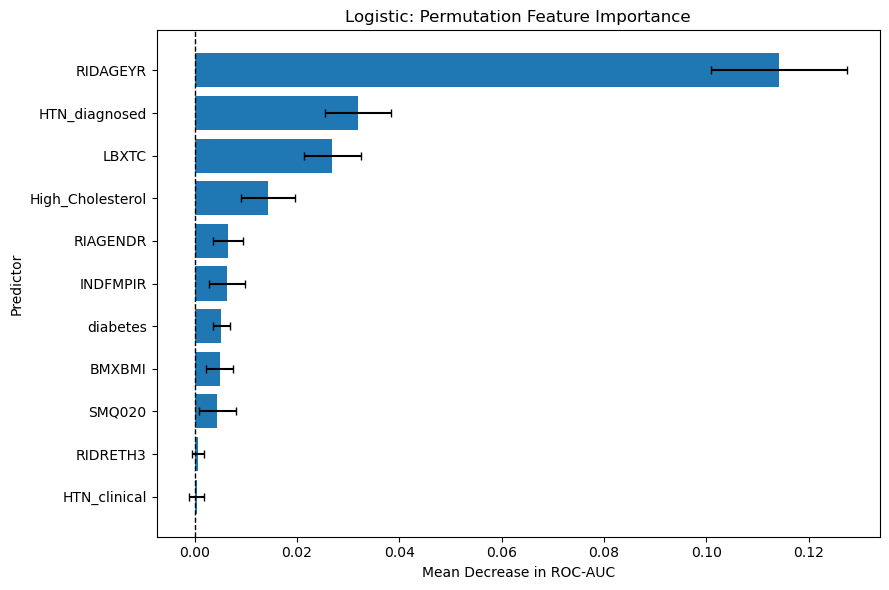

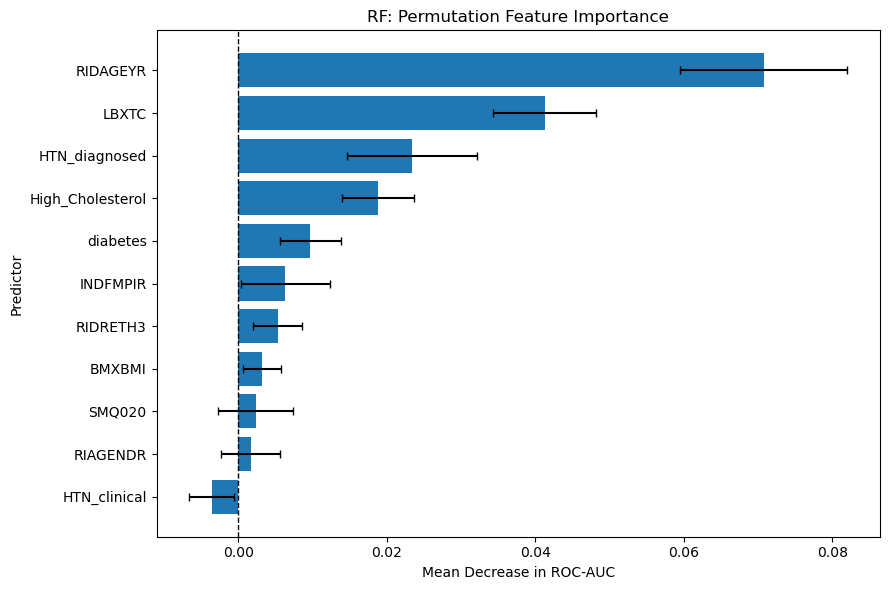

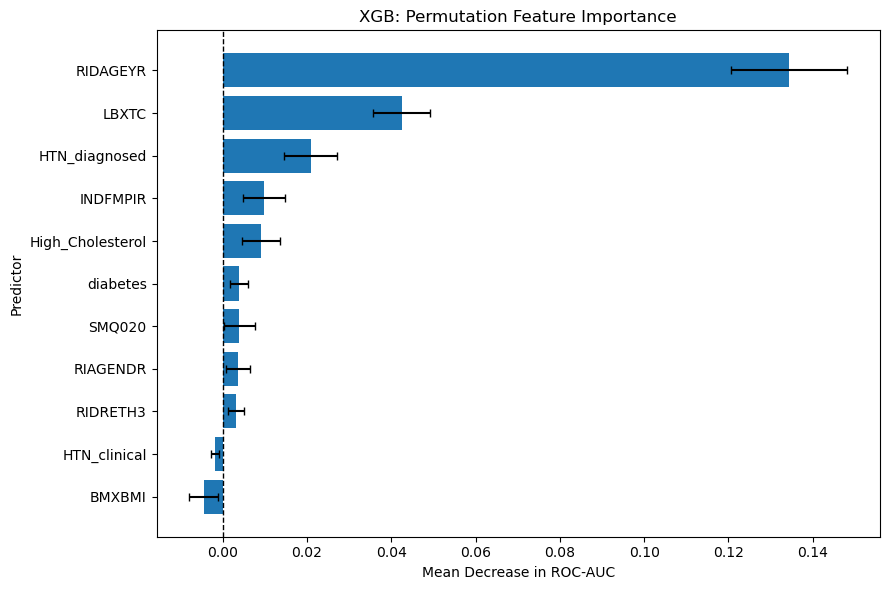


=== Feature Importance Comparison Across Models ===
                  Logistic      RF     XGB  Average_Importance
Feature                                                       
RIDAGEYR            0.1142  0.0708  0.1344              0.1065
LBXTC               0.0269  0.0412  0.0424              0.0369
HTN_diagnosed       0.0319  0.0234  0.0209              0.0254
High_Cholesterol    0.0144  0.0189  0.0091              0.0141
INDFMPIR            0.0064  0.0063  0.0098              0.0075
diabetes            0.0052  0.0097  0.0039              0.0063
RIAGENDR            0.0065  0.0017  0.0037              0.0039
SMQ020              0.0044  0.0024  0.0039              0.0036
RIDRETH3            0.0007  0.0053  0.0032              0.0031
BMXBMI              0.0049  0.0032 -0.0046              0.0012
HTN_clinical        0.0004 -0.0036 -0.0019             -0.0017


In [51]:
# ============================================================
# CVD ANALYSIS: PERMUTATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Calculate permutation importance for each model
# ------------------------------------------------------------

permutation_results_cvd = {}

for name, model in trained_models_cvd.items():

    result = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="roc_auc",
        n_repeats=20,
        random_state=42,
        n_jobs=1
    )

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Mean_Importance": result.importances_mean,
        "SD_Importance": result.importances_std
    })

    importance_df = importance_df.sort_values(
        by="Mean_Importance",
        ascending=False
    ).reset_index(drop=True)

    permutation_results_cvd[name] = importance_df

    print(f"\n=== {name} Permutation Feature Importance ===")
    print(importance_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 2. Visualize permutation importance for each model
# ------------------------------------------------------------

for name, importance_df in permutation_results_cvd.items():

    plot_df = importance_df.sort_values(
        by="Mean_Importance",
        ascending=True
    )

    plt.figure(figsize=(9, 6))

    plt.barh(
        plot_df["Feature"],
        plot_df["Mean_Importance"],
        xerr=plot_df["SD_Importance"],
        capsize=3
    )

    plt.axvline(
        x=0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    plt.title(f"{name}: Permutation Feature Importance")
    plt.xlabel("Mean Decrease in ROC-AUC")
    plt.ylabel("Predictor")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 3. Compare feature importance across models
# ------------------------------------------------------------

importance_comparison_cvd = pd.DataFrame({
    name: df.set_index("Feature")["Mean_Importance"]
    for name, df in permutation_results_cvd.items()
})

importance_comparison_cvd["Average_Importance"] = (
    importance_comparison_cvd.mean(axis=1)
)

importance_comparison_cvd = importance_comparison_cvd.sort_values(
    by="Average_Importance",
    ascending=False
)

print("\n=== Feature Importance Comparison Across Models ===")
print(importance_comparison_cvd.round(4))

### CVD risk score made through data

In [53]:
# Final logistic model refit on full data
final_logistic_cvd = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=4000))
])

final_logistic_cvd.fit(X, y)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['RIDAGEYR', 'RIAGENDR',
                                                   'INDFMPIR', 'BMXBMI',
                                                   'LBXTC', 'SMQ020',
                                                   'diabetes', 'HTN_clinical',
                                                   'HTN_diagnosed',
                                                   'High_Cholesterol']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['RIDRETH3'])])),
                ('clf', LogisticRegression(max_iter=4000))])

In [54]:
# Data-driven CVD probability score from Logistic Regression

# Generate predicted probabilities of CVD = 1
df_cvd_model["ml_risk_score"] = final_logistic_cvd.predict_proba(X)[:, 1]

# Quick check
print(df_cvd_model["ml_risk_score"].describe())

count    4441.000000
mean        0.121770
std         0.156392
min         0.000943
25%         0.015036
50%         0.048056
75%         0.173106
max         0.836617
Name: ml_risk_score, dtype: float64


In [55]:
import pandas as pd

# Create five risk groups based on predicted CVD probabilities
df_cvd_model["risk_quintile"] = pd.qcut(
    df_cvd_model["ml_risk_score"],
    q=5,
    labels=[
        "Q1 (Lowest)",
        "Q2",
        "Q3",
        "Q4",
        "Q5 (Highest)"
    ]
)

# Verify distribution across quintiles
print(df_cvd_model["risk_quintile"].value_counts().sort_index())

risk_quintile
Q1 (Lowest)     889
Q2              888
Q3              888
Q4              888
Q5 (Highest)    888
Name: count, dtype: int64


In [56]:
# Observed CVD prevalence by predicted probability quintile
cvd_by_quintile = (
    df_cvd_model
    .groupby("risk_quintile", observed=True)
    .agg(
        Participants=("CVD", "size"),
        CVD_Cases=("CVD", "sum"),
        CVD_Prevalence=("CVD", "mean"),
        Mean_Predicted_Probability=("ml_risk_score", "mean")
    )
)

# Convert proportions to percentages
cvd_by_quintile["CVD_Prevalence"] *= 100
cvd_by_quintile["Mean_Predicted_Probability"] *= 100

print(cvd_by_quintile.round(2))

               Participants  CVD_Cases  CVD_Prevalence  \
risk_quintile                                            
Q1 (Lowest)             889        4.0            0.45   
Q2                      888       12.0            1.35   
Q3                      888       45.0            5.07   
Q4                      888      128.0           14.41   
Q5 (Highest)            888      352.0           39.64   

               Mean_Predicted_Probability  
risk_quintile                              
Q1 (Lowest)                          0.68  
Q2                                   1.95  
Q3                                   5.14  
Q4                                  13.98  
Q5 (Highest)                        39.14  


## CVD Testing

In [58]:
# CVD testing: inferential logistic regression (All 11 predictors)

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Copy cleaned dataset
# Use the same complete-case sample as the 11-predictor ML models
df_cvd_or = df_cvd_model.copy()

# 2. Convert categorical variables
df_cvd_or["RIAGENDR"] = df_cvd_or["RIAGENDR"].astype("category")
df_cvd_or["RIDRETH3"] = df_cvd_or["RIDRETH3"].astype("category")

# 3. Logistic regression formula
# (IMPORTANT: includes all 11 CVD predictors)
formula = """
CVD ~ RIDAGEYR + BMXBMI + LBXTC + INDFMPIR +
C(RIAGENDR) + C(RIDRETH3) + SMQ020 + diabetes +
HTN_clinical + HTN_diagnosed + High_Cholesterol
"""

# 4. Fit model with robust SE
model_cvd = smf.logit(
    formula=formula,
    data=df_cvd_or
).fit(cov_type="HC3")

print(model_cvd.summary())

# 5. Odds ratio table
params = model_cvd.params
conf = model_cvd.conf_int()
conf.columns = ["2.5%", "97.5%"]
pvals = model_cvd.pvalues

or_table = pd.DataFrame({
    "Coefficient": params,
    "OR": np.exp(params),
    "Lower CI": np.exp(conf["2.5%"]),
    "Upper CI": np.exp(conf["97.5%"]),
    "p-value": pvals
})

# Significance flag
or_table["Significant_0.05"] = or_table["p-value"] < 0.05

print("\n=== Odds Ratio Table for CVD Model (All 11 Predictors) ===")
print(or_table)

Optimization terminated successfully.
         Current function value: 0.272134
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                    CVD   No. Observations:                 4441
Model:                          Logit   Df Residuals:                     4425
Method:                           MLE   Df Model:                           15
Date:                Fri, 23 Oct 2026   Pseudo R-squ.:                  0.2656
Time:                        18:39:49   Log-Likelihood:                -1208.5
converged:                       True   LL-Null:                       -1645.5
Covariance Type:                  HC3   LLR p-value:                1.296e-176
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -5.4577      0.562     -9.717      0.000      -6.559      -4.357
C(RIA

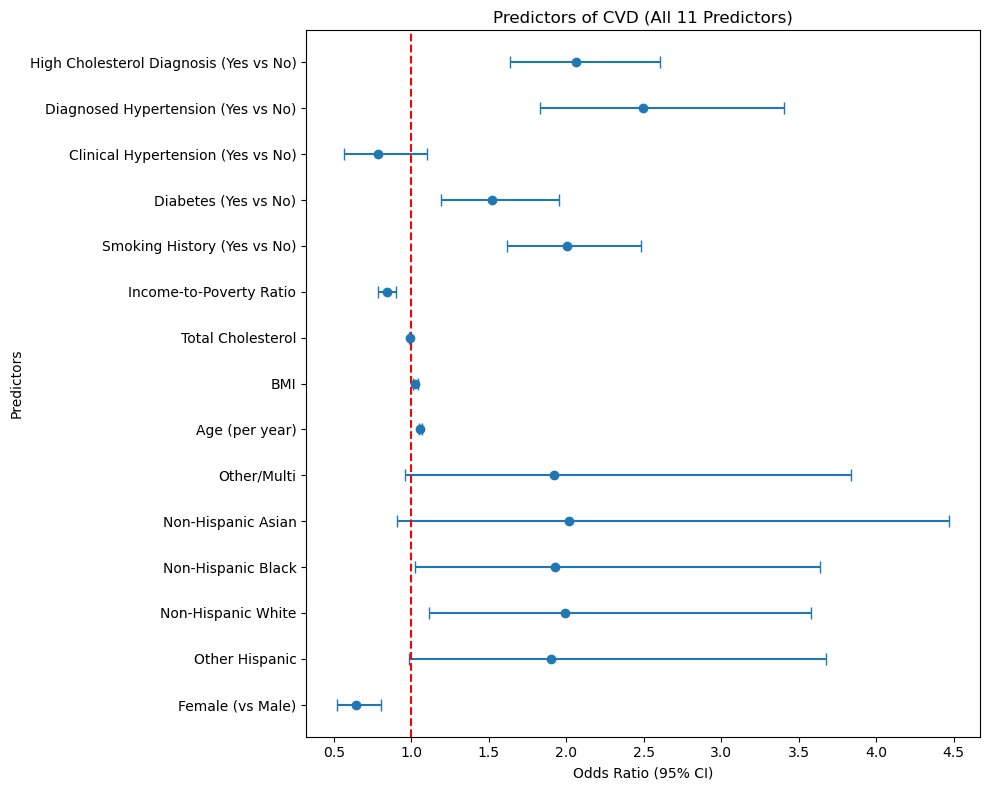

In [59]:
# ============================================================
# FOREST PLOT FOR CVD LOGISTIC REGRESSION (ALL 11 PREDICTORS)
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create CVD odds-ratio plotting table
# ------------------------------------------------------------

# Use the OR table created by the CVD logistic regression
or_cvd = or_table.copy()

# Remove intercept
or_cvd = or_cvd.drop(
    index="Intercept",
    errors="ignore"
)

# ------------------------------------------------------------
# 2. Create readable predictor labels
# ------------------------------------------------------------

label_map_cvd = {
    "RIDAGEYR": "Age (per year)",
    "BMXBMI": "BMI",
    "LBXTC": "Total Cholesterol",
    "INDFMPIR": "Income-to-Poverty Ratio",
    "SMQ020": "Smoking History (Yes vs No)",
    "diabetes": "Diabetes (Yes vs No)",
    "HTN_clinical": "Clinical Hypertension (Yes vs No)",
    "HTN_diagnosed": "Diagnosed Hypertension (Yes vs No)",
    "High_Cholesterol": "High Cholesterol Diagnosis (Yes vs No)",
    "C(RIAGENDR)[T.1]": "Female (vs Male)",
    "C(RIDRETH3)[T.2.0]": "Other Hispanic",
    "C(RIDRETH3)[T.3.0]": "Non-Hispanic White",
    "C(RIDRETH3)[T.4.0]": "Non-Hispanic Black",
    "C(RIDRETH3)[T.6.0]": "Non-Hispanic Asian",
    "C(RIDRETH3)[T.7.0]": "Other/Multi"
}

or_cvd["label"] = or_cvd.index.map(
    lambda x: label_map_cvd.get(x, x)
)

# ------------------------------------------------------------
# 3. Forest plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.errorbar(
    x=or_cvd["OR"],
    y=or_cvd["label"],
    xerr=[
        or_cvd["OR"] - or_cvd["Lower CI"],
        or_cvd["Upper CI"] - or_cvd["OR"]
    ],
    fmt="o",
    capsize=4
)

# Reference line for no association
plt.axvline(
    x=1,
    linestyle="--",
    color="red"
)

plt.xlabel("Odds Ratio (95% CI)")
plt.ylabel("Predictors")
plt.title("Predictors of CVD (All 11 Predictors)")

plt.tight_layout()
plt.show()